# 11 — Visualisations and Business Recommendations
**Day 11 · Phase 5**

This notebook turns the analysis into material for the retailer's pricing and marketing teams:
1. three business-facing charts built from actual listing prices and the final model,
2. a gallery of the required project visualisations (generated in notebooks 02–10, saved in `reports/figures/`),
3. recommendations, each tied to a specific result.

Throughout, **association is not causation**: the data shows which specifications go with higher prices in the
market, not that adding a specification would by itself justify a higher price.

In [1]:
import sys, warnings
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.plot_style import (apply_style, save_fig, rupee_axis, PALETTE, PRIMARY, ACCENT,
                            NEUTRAL, DIVERGING, SEQUENTIAL)

apply_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
RANDOM_STATE = 42

from src.feature_engineering import SpecFeatureBuilder
from src.preprocessing import MODEL_INPUT_COLUMNS

clean = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "phones_clean.csv")
eng = SpecFeatureBuilder().transform(clean[MODEL_INPUT_COLUMNS])
df = pd.concat([clean[["model", "price"]], eng], axis=1)
tier_names = {0: "Entry", 1: "Mainstream", 2: "Upper-mid", 3: "Flagship"}
df["tier"] = df["processor_tier"].map(tier_names)
print(df.shape)

(516, 15)


## 1. Which combinations of specifications appear in higher-priced phones?

In [2]:
df["price_segment"] = pd.qcut(df["price"], 4, labels=["Bottom 25 %", "Lower-mid 25 %", "Upper-mid 25 %", "Top 25 %"])
profile = df.groupby("price_segment", observed=True).agg(
    price_range=("price", lambda p: f"₹{p.min()/1000:.1f}k–{p.max()/1000:.1f}k"),
    phones=("price", "size"),
    median_storage_gb=("storage_gb", "median"),
    median_ram_gb=("ram_gb", "median"),
    share_flagship_or_upper_mid_chip=("processor_tier", lambda t: (t >= 2).mean()),
    share_5g=("is_5g", "mean"),
    median_front_camera_mp=("front_camera_mp", "median"),
    median_battery_mah=("battery_mah", "median"),
    share_qualcomm=("processor_vendor", lambda v: (v == "Qualcomm").mean()),
)
profile.T

price_segment,Bottom 25 %,Lower-mid 25 %,Upper-mid 25 %,Top 25 %
price_range,₹5.0k–9.5k,₹9.7k–14.0k,₹14.4k–20.0k,₹20.0k–81.0k
phones,130,135,122,129
median_storage_gb,64.000,64.000,128.000,128.000
median_ram_gb,4.000,4.000,6.000,8.000
share_flagship_or_upper_mid_chip,0.000,0.007,0.115,0.729
share_5g,0.000,0.141,0.615,0.736
median_front_camera_mp,5.000,8.000,16.000,16.000
median_battery_mah,"5,000.000","5,000.000","5,000.000","4,980.000"
share_qualcomm,0.038,0.141,0.451,0.388


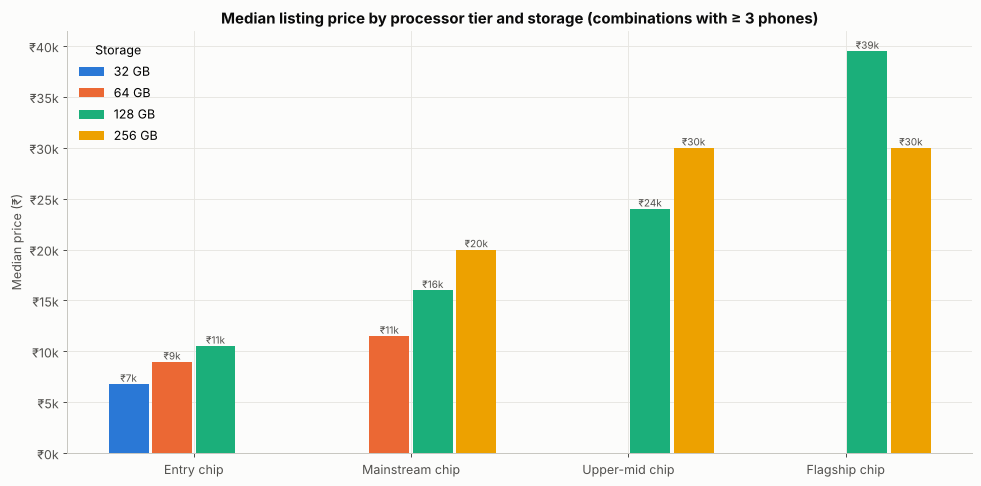

In [3]:
combo = (df.dropna(subset=["tier"]).groupby(["tier", "storage_gb"])["price"]
         .agg(phones="size", median_price="median").reset_index())
combo = combo[combo["phones"] >= 3]
order_t = ["Entry", "Mainstream", "Upper-mid", "Flagship"]
fig, ax = plt.subplots(figsize=(11, 5.5))
storages = sorted(combo["storage_gb"].unique())
w = 0.8 / len(storages)
for i, st in enumerate(storages):
    d = combo[combo["storage_gb"] == st].set_index("tier").reindex(order_t)
    x = np.arange(len(order_t)) + (i - (len(storages) - 1) / 2) * w
    ax.bar(x, d["median_price"], width=w * 0.92, color=PALETTE[i], label=f"{int(st)} GB")
    for xi, (v, n) in zip(x, zip(d["median_price"], d["phones"])):
        if pd.notna(v):
            ax.text(xi, v, f"₹{v/1000:.0f}k", ha="center", va="bottom", fontsize=8, color="#52514e")
ax.set_xticks(range(len(order_t)), [f"{t} chip" for t in order_t])
ax.set(title="Median listing price by processor tier and storage (combinations with ≥ 3 phones)", ylabel="Median price (₹)")
rupee_axis(ax); ax.legend(title="Storage"); fig.tight_layout(); save_fig(fig, "biz_price_ladder")

**Interpretation.**
- The **top 25 %** (₹20k–81k) is defined by **upper-mid/flagship chips (73 % of phones vs 0 % in the bottom
  quarter)**, 8 GB RAM, 128 GB+ storage, 16 MP front cameras and 5G (74 %).
- The **bottom 25 %** (₹5k–9.5k) has no upper-mid/flagship chips and no 5G, with 4 GB RAM, 64 GB and 5 MP selfie
  cameras.
- The step from lower-mid to upper-mid (~₹14k) is where **5G jumps from 14 % to 62 %** and median storage doubles.
- Median battery is 5,000 mAh in every quarter. Battery differences are in the tails (EDA: 6,000 mAh phones median
  ~₹9.7k; 4,000–4,500 mAh ~₹28k).
- The price ladder shows that **processor tier sets the price band and storage moves the price within it**.
  One exception: among flagship chips, the 128 GB group (median ~₹39k) is *above* the 256 GB group (~₹30k), because
  the 128 GB flagships include the iPhone 14 Plus, Pixel 7/7a, Galaxy S22 Plus and Z Flip3 (brand premium), while
  the 256 GB group is mostly value flagships (POCO F5, Redmi K50i, realme GT 2, Motorola Edge 40), though it also
  contains the S23. Brand matters as much as storage at the top end.

## 2. What is each specification upgrade associated with?

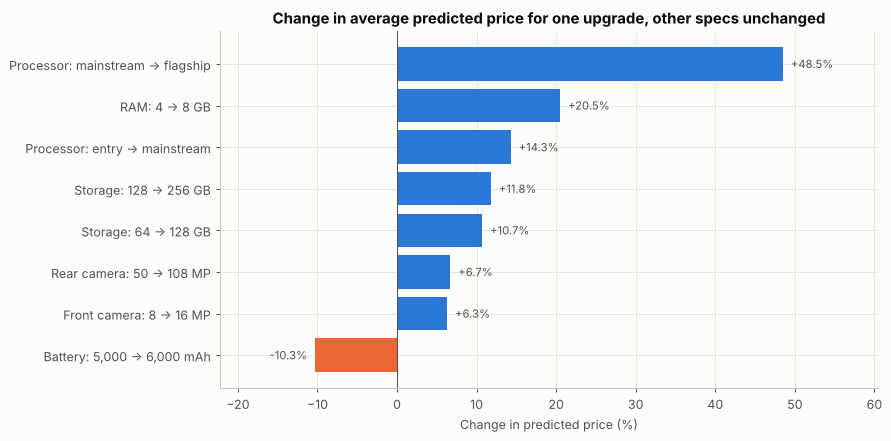

upgrade,Processor: mainstream → flagship,Processor: entry → mainstream,RAM: 4 → 8 GB,Storage: 128 → 256 GB,Storage: 64 → 128 GB,Front camera: 8 → 16 MP,Rear camera: 50 → 108 MP,"Battery: 5,000 → 6,000 mAh"
effect_%,48.500,14.300,20.500,11.800,10.700,6.300,6.700,-10.300


In [4]:
from src.train import load_model_ready_data, xy, final_pipeline
train, test = load_model_ready_data()
X_tr, y_tr, _ = xy(train)
model = final_pipeline().fit(X_tr, y_tr)
pop = clean[MODEL_INPUT_COLUMNS]

def avg_pred(column, value):
    d = pop.copy(); d[column] = value
    return np.exp(np.mean(np.log(model.predict(d))))

upgrades = pd.DataFrame([
    ("Processor: mainstream → flagship", avg_pred("processor", "Qualcomm Snapdragon 8 Gen 1") / avg_pred("processor", "Qualcomm Snapdragon 680") - 1),
    ("Processor: entry → mainstream", avg_pred("processor", "Qualcomm Snapdragon 680") / avg_pred("processor", "Mediatek Helio G35") - 1),
    ("RAM: 4 → 8 GB", avg_pred("ram_gb", 8) / avg_pred("ram_gb", 4) - 1),
    ("Storage: 128 → 256 GB", avg_pred("storage_gb", 256) / avg_pred("storage_gb", 128) - 1),
    ("Storage: 64 → 128 GB", avg_pred("storage_gb", 128) / avg_pred("storage_gb", 64) - 1),
    ("Front camera: 8 → 16 MP", avg_pred("front_camera_mp", 16) / avg_pred("front_camera_mp", 8) - 1),
    ("Rear camera: 50 → 108 MP", avg_pred("rear_camera_mp", 108) / avg_pred("rear_camera_mp", 50) - 1),
    ("Battery: 5,000 → 6,000 mAh", avg_pred("battery_mah", 6000) / avg_pred("battery_mah", 5000) - 1),
], columns=["upgrade", "effect"]).set_index("upgrade")
upgrades["effect_%"] = (upgrades["effect"] * 100).round(1)
u = upgrades.sort_values("effect")
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(u.index, u["effect_%"], color=[ACCENT if v < 0 else PRIMARY for v in u["effect_%"]])
for i, v in enumerate(u["effect_%"]):
    ax.text(v + (1 if v >= 0 else -1), i, f"{v:+.1f}%", va="center", ha="left" if v >= 0 else "right", fontsize=9, color="#52514e")
ax.axvline(0, color="#52514e", lw=0.8)
ax.set(title="Change in average predicted price for one upgrade, other specs unchanged", xlabel="Change in predicted price (%)",
       xlim=(u["effect_%"].min() - 12, u["effect_%"].max() + 12))
fig.tight_layout(); save_fig(fig, "biz_upgrade_effects")
upgrades[["effect_%"]].T

**Interpretation.** The largest step is **mainstream → flagship processor (+48.5 %)**, then **RAM 4 → 8 GB
(+20.5 %)**, entry → mainstream chip (+14.3 %) and each **storage** doubling (+11–12 %). Camera upgrades are worth
~6–7 %. The rear-camera value (+6.7 %) should be read with care: Day 10 showed rear MP doesn't improve predictions on
unseen phones. A bigger battery goes with a *lower* price (−10.3 %). These are differences in what
the market charges for phones with these specs, averaged over the dataset, not a guarantee of what a single upgrade
earns.

## 3. Can the model be used for preliminary price estimation?

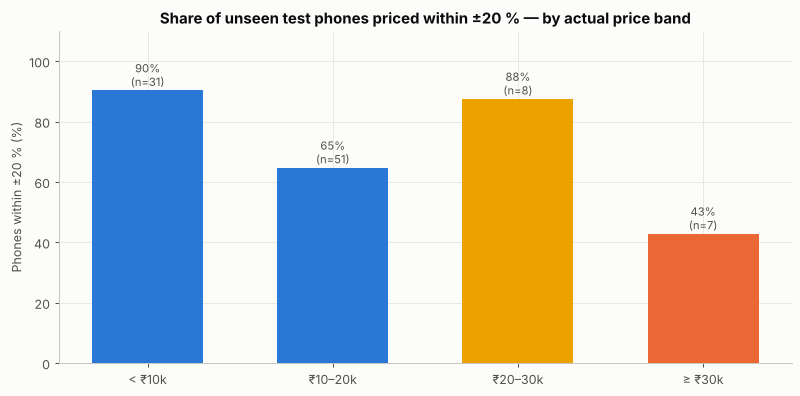

,test phones,MAE (₹),median % error,within ±20 %
band,,,,
< ₹10k,31.000,796.800,8.500,90.300
₹10–20k,51.000,"2,601.300",11.700,64.700
₹20–30k,8.000,"3,425.600",15.300,87.500
≥ ₹30k,7.000,"12,351.300",28.700,42.900


In [5]:
X_te, y_te, _ = xy(test)
pred = pd.Series(model.predict(X_te), index=X_te.index)
band = pd.cut(y_te, [0, 10000, 20000, 30000, 100000], labels=["< ₹10k", "₹10–20k", "₹20–30k", "≥ ₹30k"])
rel = pd.DataFrame({"y": y_te, "p": pred, "band": band}).groupby("band", observed=True).apply(
    lambda d: pd.Series({"test phones": len(d), "MAE (₹)": np.mean(np.abs(d.y - d.p)),
                         "median % error": np.median(np.abs(d.y - d.p) / d.y) * 100,
                         "within ±20 %": np.mean(np.abs(d.y - d.p) / d.y <= 0.2) * 100}), include_groups=False)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(rel.index.astype(str), rel["within ±20 %"], color=[PRIMARY, PRIMARY, PALETTE[3], ACCENT], width=0.6)
for i, (v, n) in enumerate(zip(rel["within ±20 %"], rel["test phones"])):
    ax.text(i, v + 1.5, f"{v:.0f}%\n(n={n:.0f})", ha="center", fontsize=9, color="#52514e")
ax.set(title="Share of unseen test phones priced within ±20 % — by actual price band", ylabel="Phones within ±20 % (%)", ylim=(0, 110))
fig.tight_layout(); save_fig(fig, "biz_reliability_by_band")
rel.round(1)

**Interpretation.**
- **Under ₹10k:** 90 % of unseen phones within ±20 % (median error 8.5 %, MAE ₹797). Reliable.
- **₹10–20k:** 65 % within ±20 % (median error 11.7 %). Usable, but the over-priced older flagships sit here.
- **₹20–30k:** 88 % within ±20 %, but only 8 test phones, so treat it as indicative.
- **≥ ₹30k:** only 43 % within ±20 % (median error 29 %) and estimates are systematically too low.

So the model is suitable for **preliminary estimates in the budget and mainstream segments**, with a human check
for premium phones.

## 4. Required project visualisations (gallery)

Price distribution: reports/figures/eda_price_distribution.png
Feature correlation heatmap: reports/figures/eda_correlation_heatmap.png
PCA explained variance: reports/figures/fs_pca_explained_variance.png
Model performance comparison: reports/figures/eval_model_comparison.png
Actual vs predicted: reports/figures/eval_actual_vs_predicted.png
Residual plot: reports/figures/eval_residuals.png
Important feature ranking (permutation): reports/figures/final_permutation_importance.png
Shapley summary plot: reports/figures/final_shapley_summary.png


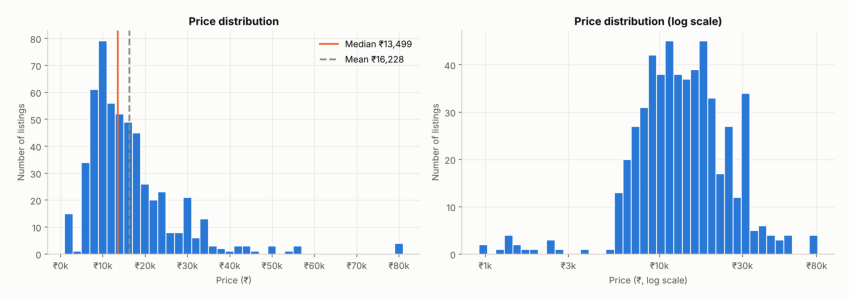

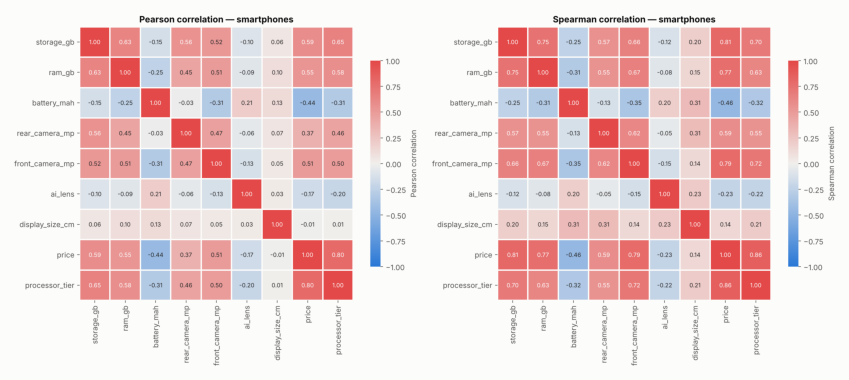

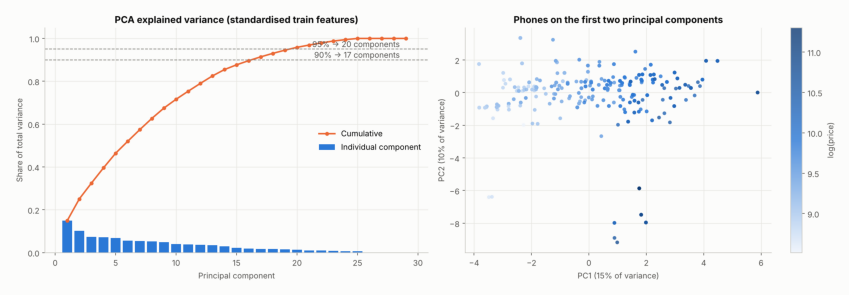

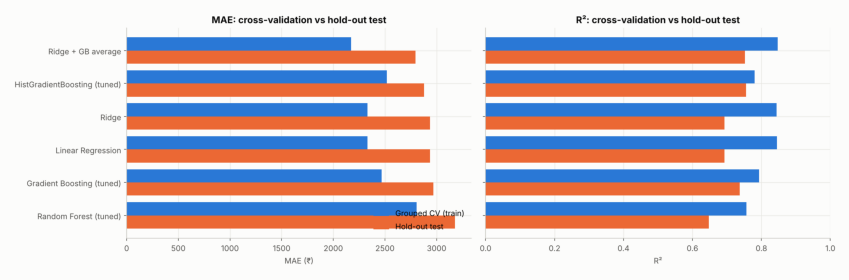

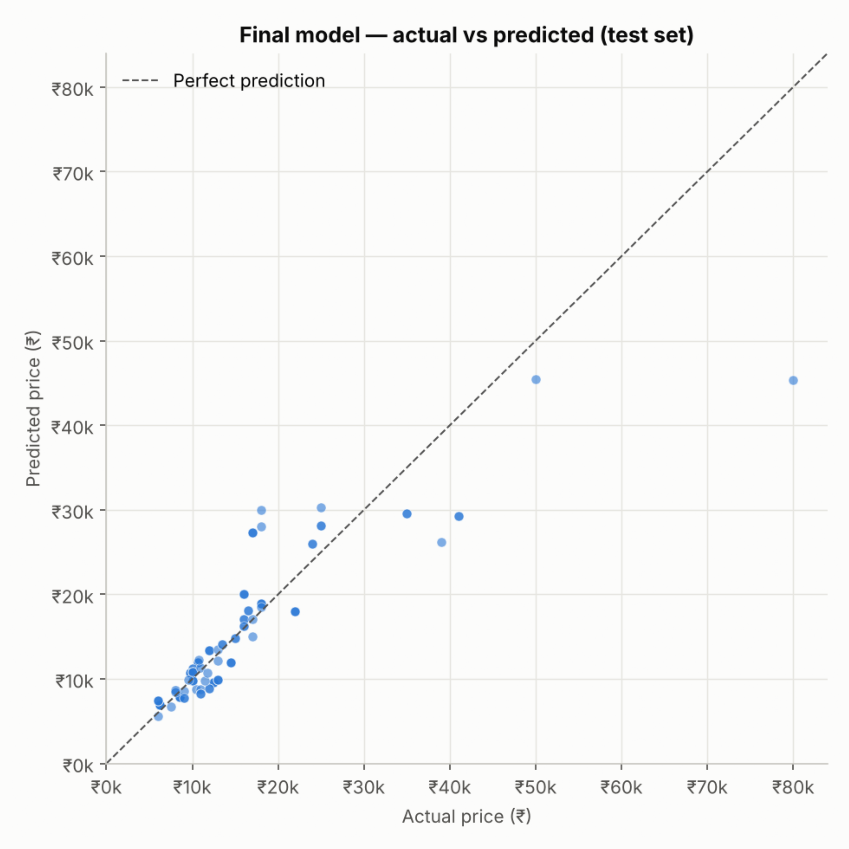

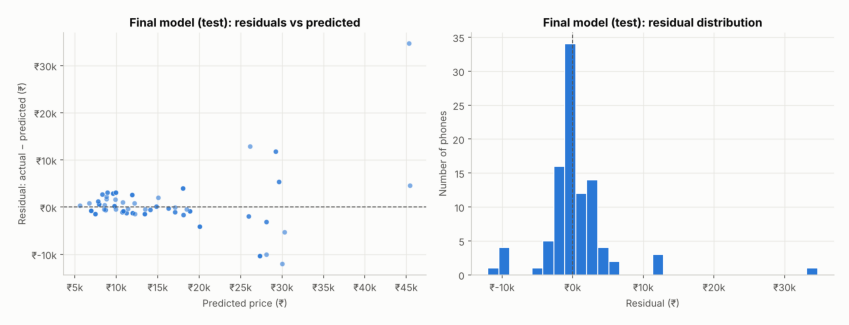

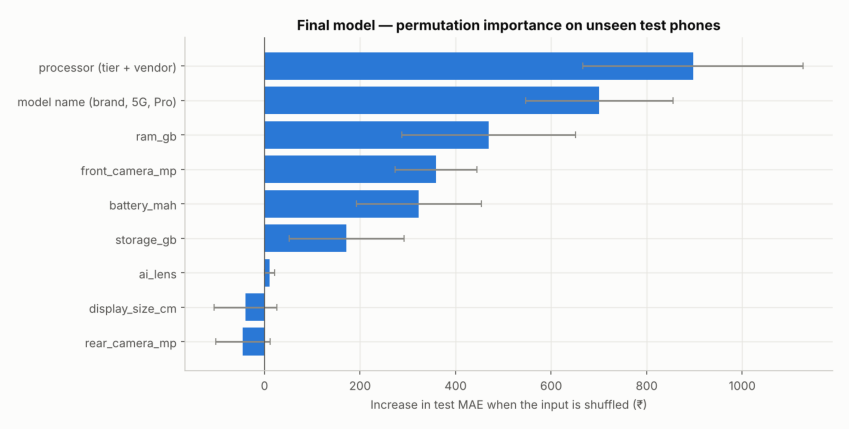

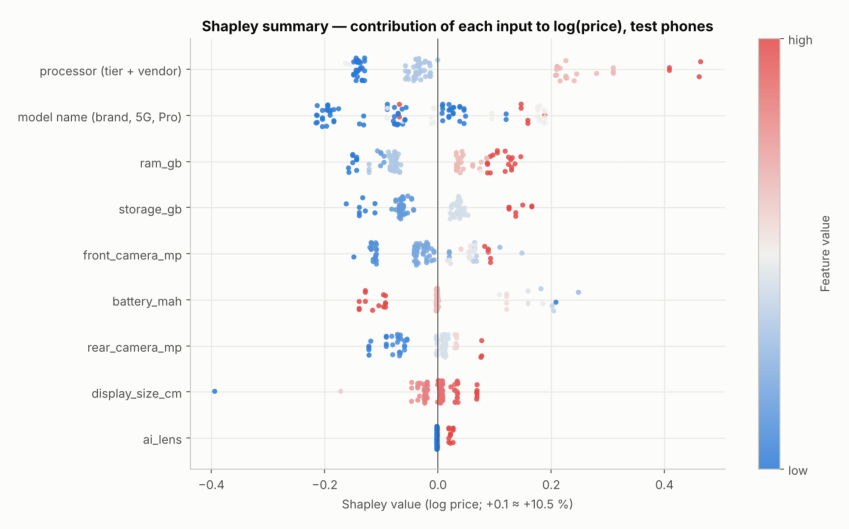

In [6]:
from PIL import Image
gallery = [
    ("Price distribution", "eda_price_distribution"),
    ("Feature correlation heatmap", "eda_correlation_heatmap"),
    ("PCA explained variance", "fs_pca_explained_variance"),
    ("Model performance comparison", "eval_model_comparison"),
    ("Actual vs predicted", "eval_actual_vs_predicted"),
    ("Residual plot", "eval_residuals"),
    ("Important feature ranking (permutation)", "final_permutation_importance"),
    ("Shapley summary plot", "final_shapley_summary"),
]
for title, name in gallery:
    img = Image.open(PROJECT_ROOT / "reports" / "figures" / f"{name}.png")
    w, h = img.size
    fig, ax = plt.subplots(figsize=(12, 12 * h / w))
    ax.imshow(img); ax.axis("off")
    print(f"{title}: reports/figures/{name}.png")

Each figure's interpretation sits in the notebook that generated it (02 EDA, 05 PCA, 09 evaluation, 10
explainability). All are saved at 150 dpi in `reports/figures/`.

## 5. Business recommendations

### A. Pricing strategy
1. **Anchor the price band on the processor tier.** It's the strongest predictor (top by permutation and Shapley;
   mainstream → flagship ≈ +49 % in the model). When positioning a new listing, identify its chip tier first, then
   adjust for memory.
2. **Treat RAM and storage as within-band adjustments.** 4 → 8 GB RAM ≈ +20 %; each storage doubling ≈ +11–12 %.
   These are the variant-pricing levers (e.g. 128 GB vs 256 GB of the same model).
3. **Account for brand.** Brand/model-name signals are the 2nd most important input. Similar hardware sells at
   clearly different levels across brands (Infinix/POCO below average, Samsung/OPPO above, Google/Apple far above).
   A spec-only price should be adjusted for brand positioning.
4. **Don't price on rear-camera megapixels.** MP count adds no predictive value on unseen phones: 12 MP flagships
   outsell 50–200 MP budget phones on price.
5. **Watch older flagships.** Phones with previous-generation high-tier chips (realme X3, Galaxy F23) sell well below
   what their chip suggests. Add launch date to the data before relying on chip tier for these.

### B. Marketing
6. **Lead with processor and memory** for mid-range and premium listings: these are the specs the market prices
   most consistently.
7. **Market large batteries as a value feature.** 6,000 mAh phones are budget phones (≈ −10 % vs 5,000 mAh in the
   model). Battery is a reason to buy at a budget price point, not a justification for a premium.
8. **Promote 5G and front-camera upgrades** in the ₹10–20k segment, where they distinguish otherwise similar phones.
9. **High-MP rear cameras** can attract attention but shouldn't be the main justification for a higher price.

### C. Using the model responsibly
10. **Use it for preliminary estimates** in the budget/mainstream segment (typical error ~₹800–1,800 below ₹15k;
    64 % of unseen phones within ±₹2,000), not as a final price.
11. **Require a human review for phones above ~₹25k**, older flagships, new brands, and specs outside the training
    range (RAM > 8 GB, storage > 256 GB). The app shows a warning for out-of-range inputs.
12. **Retrain regularly** (quarterly or when new chip generations arrive); prices of a given spec fall over time and
    this dataset is a single snapshot.
13. **Improve the data**: collect launch date, true RAM (incl. 12 GB+), refresh rate, charging speed, build
    materials and more premium listings. The learning curve shows the model is still data-limited.

### What the results do **not** show
- That adding a spec *causes* a higher achievable price (observational data; specs are bundled).
- Anything about feature phones (excluded), or about prices at other times: the data is a single Flipkart
  snapshot of phones that are mostly 2021–2023 launches, with no listing dates.